In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_style('whitegrid')
plt.rcParams['axes.titlecolor'] = '#CC0000'
plt.rcParams['axes.edgecolor'] = '#CC0000'

Task 1: Data Loading & EDA

In [2]:
df = pd.read_csv('Mall_Customers.csv')
display(df.head()); df.info(); display(df.describe())

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [3]:
df = df.rename(columns={'Annual Income (k$)':'Annual_Income','Spending Score (1-100)':'Spending_Score'}).drop(columns='CustomerID')
df['Gender'] = LabelEncoder().fit_transform(df['Gender'])   # Female=0, Male=1
df.head()

,Gender,Age,Annual_Income,Spending_Score
0,1,19,15,39
1,1,21,15,81
2,0,20,16,6
3,0,23,16,77
4,0,31,17,40


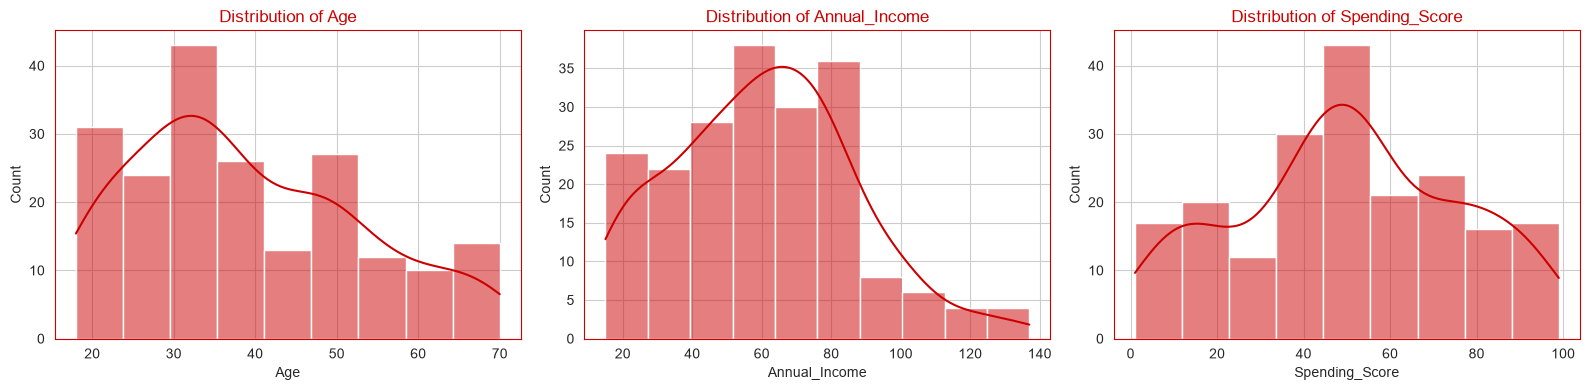

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16,4))
for a, c in zip(ax, ['Age','Annual_Income','Spending_Score']):
    sns.histplot(df[c], kde=True, ax=a, color='#CC0000')
    a.set_title(f'Distribution of {c}'); a.set_xlabel(c); a.set_ylabel('Count')
plt.tight_layout(); plt.show()

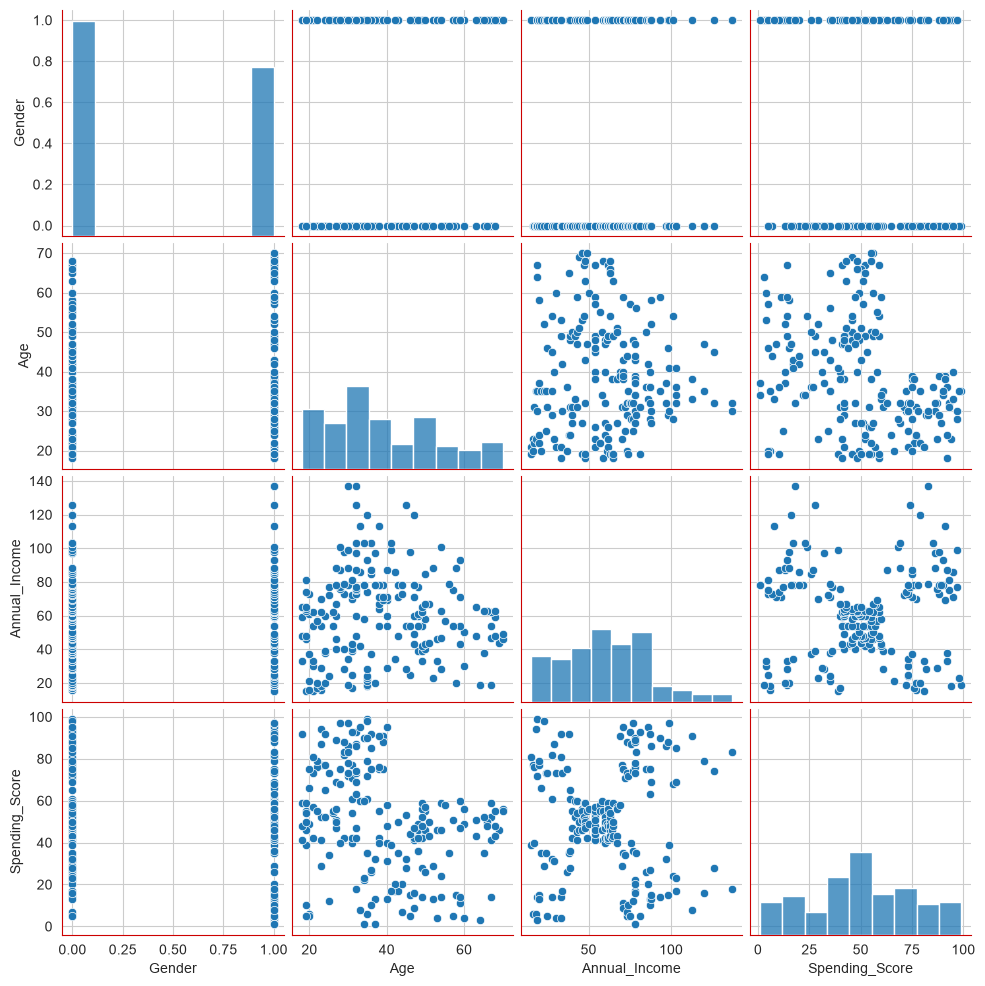

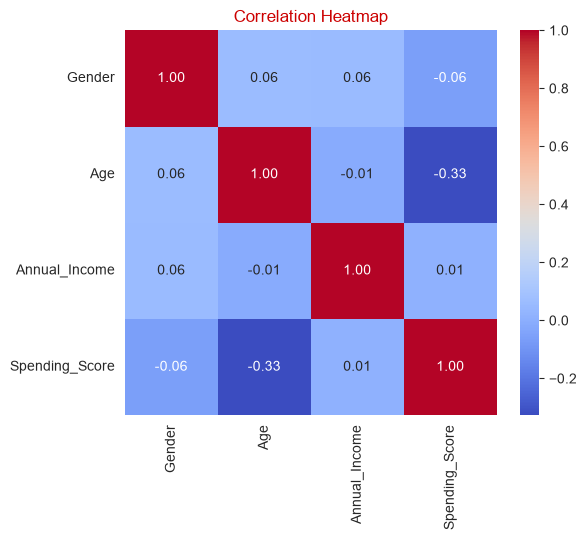

In [5]:
sns.pairplot(df, hue=None); plt.show()
plt.figure(figsize=(6,5))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap'); plt.show()

EDA Summary

Annual_Income vs Spending_Score in the pairplot shows 5 visible blobs. This is the only pair with clear natural grouping.
Age shows a mild negative relationship with Spending_Score (younger customers spend more).
Correlations between features are weak overall, so no feature is redundant.
Gender is nearly uncorrelated with everything, so it adds little to separation.
Annual_Income vs Spending_Score is the best pair because it is the only one where the groups are compact and well separated.

Task 2: Scaling & Feature Selection

In [6]:
num = ['Age','Annual_Income','Spending_Score']
df_scaled = pd.DataFrame(StandardScaler().fit_transform(df[num]), columns=num)
df_scaled['Gender'] = df['Gender']
df_2f = df_scaled[['Annual_Income','Spending_Score']]
df_2f.head()

,Annual_Income,Spending_Score
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


Using all 4 features is valid, but the main tasks use the 2-feature subset df_2f for clear 2D visualisation without PCA.
Why scaling? K-Means, Hierarchical and DBSCAN are all distance-based. Without scaling, a feature with a larger raw range dominates every distance calculation. Here Annual_Income (about 15 to 137) would outweigh Spending_Score (1 to 100). StandardScaler gives each feature mean 0 and std 1, so each contributes fairly. Gender is already binary, so it isn’t scaled.

Task 3: K-Means

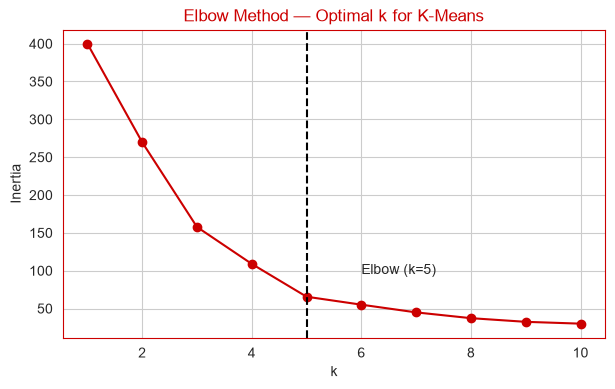

In [7]:
inertia = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(df_2f).inertia_ for k in range(1,11)]
plt.figure(figsize=(7,4))
plt.plot(range(1,11), inertia, 'o-', color='#CC0000')
plt.axvline(5, ls='--', color='black'); plt.annotate('Elbow (k=5)', (5, inertia[4]), xytext=(6, inertia[4]+30))
plt.title('Elbow Method — Optimal k for K-Means'); plt.xlabel('k'); plt.ylabel('Inertia'); plt.show()

Inertia is the sum of squared distances from each point to its cluster centroid, and it measures how tight the clusters are. It always falls as k grows. The elbow is where adding another cluster stops giving a big drop, so extra clusters are just splitting already-compact groups. The elbow here is at k=5.

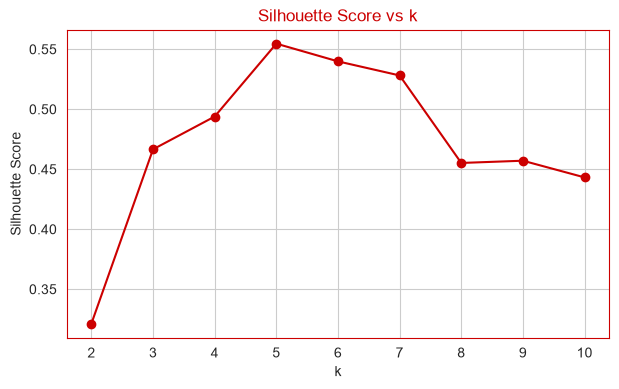

5 {2: 0.3212707813918878, 3: 0.46658474419000145, 4: 0.4939069237513199, 5: 0.5546571631111091, 6: 0.5398800926790663, 7: 0.5281492781108291, 8: 0.4552147906587443, 9: 0.4570853966942764, 10: 0.4431713026508046}


In [8]:
sil = {k: silhouette_score(df_2f, KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(df_2f)) for k in range(2,11)}
plt.figure(figsize=(7,4))
plt.plot(list(sil), list(sil.values()), 'o-', color='#CC0000')
plt.title('Silhouette Score vs k'); plt.xlabel('k'); plt.ylabel('Silhouette Score'); plt.show()
print(max(sil, key=sil.get), sil)

The silhouette score measures how well each point fits its own cluster compared with the nearest other cluster (higher is better). Both methods point to k=5. If your silhouette plot peaks elsewhere, write one line here explaining why. For example, silhouette favours well-separated clusters, while the elbow looks at compactness.

In [9]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10).fit(df_2f)
df['KMeans_Cluster'] = kmeans.labels_

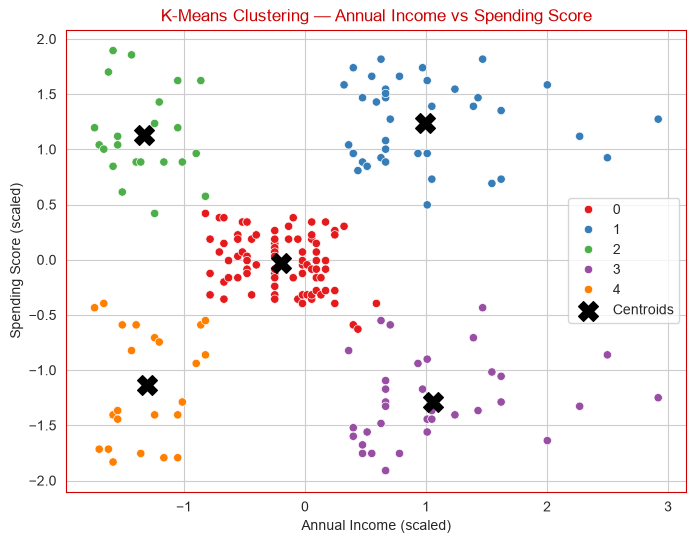

In [10]:
plt.figure(figsize=(8,6))
sns.scatterplot(x=df_2f['Annual_Income'], y=df_2f['Spending_Score'], hue=df['KMeans_Cluster'], palette='Set1')
plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], c='black', marker='X', s=200, label='Centroids')
plt.title('K-Means Clustering — Annual Income vs Spending Score')
plt.xlabel('Annual Income (scaled)'); plt.ylabel('Spending Score (scaled)'); plt.legend(); plt.show()

In [14]:
km_profile = df.groupby('KMeans_Cluster')[['Age','Annual_Income','Spending_Score']].mean()
km_profile.style.background_gradient(cmap='Reds').format('{:.1f}')

,Age,Annual_Income,Spending_Score
KMeans_Cluster,,,
0,42.7,55.3,49.5
1,32.7,86.5,82.1
2,25.3,25.7,79.4
3,41.1,88.2,17.1
4,45.2,26.3,20.9


Segment names. Cluster numbers change between runs, so match them to your table:

High income, high spend: loyalty and VIP rewards.
High income, low spend: personalised offers to convert them.
Mid income, mid spend: the largest group, so keep them engaged with seasonal promotions.
Low income, high spend (younger): budget deals and trend-driven offers.
Low income, low spend: low-cost, discount-led marketing.

Task 4: Agglomerative Hierarchical Clustering

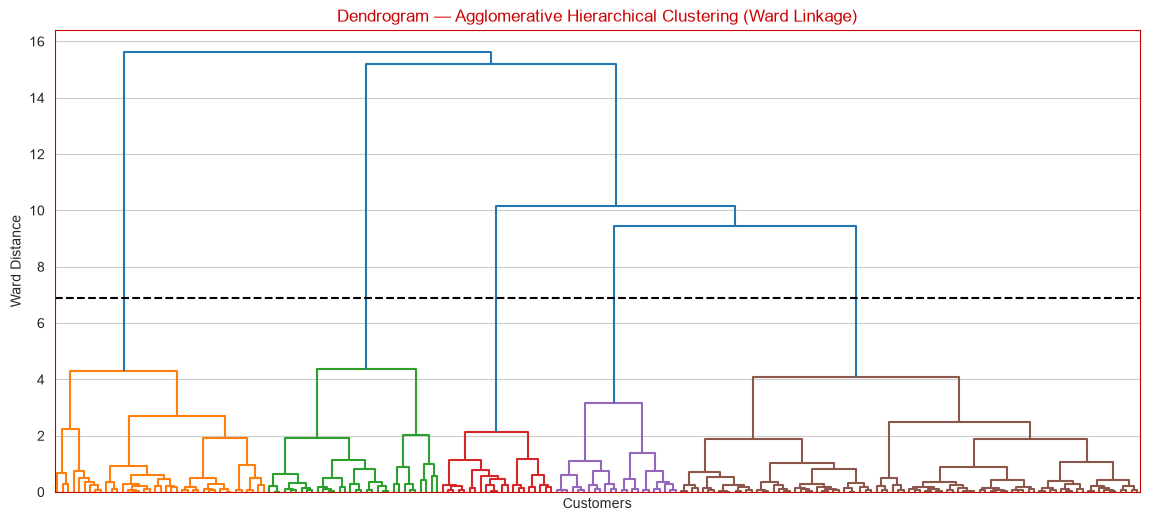

In [15]:
Z = linkage(df_2f, method='ward')
cut = (Z[-5,2] + Z[-4,2]) / 2
plt.figure(figsize=(14,6))
dendrogram(Z, no_labels=True, color_threshold=cut)
plt.axhline(cut, ls='--', color='black')
plt.title('Dendrogram — Agglomerative Hierarchical Clustering (Ward Linkage)')
plt.xlabel('Customers'); plt.ylabel('Ward Distance'); plt.show()

Ward linkage merges the two clusters whose merge causes the smallest increase in total within-cluster variance. To read the dendrogram, find the longest vertical stretch that no horizontal merge line crosses, and cut there. Counting the vertical lines the cut crosses gives the number of clusters, which is 5 here.

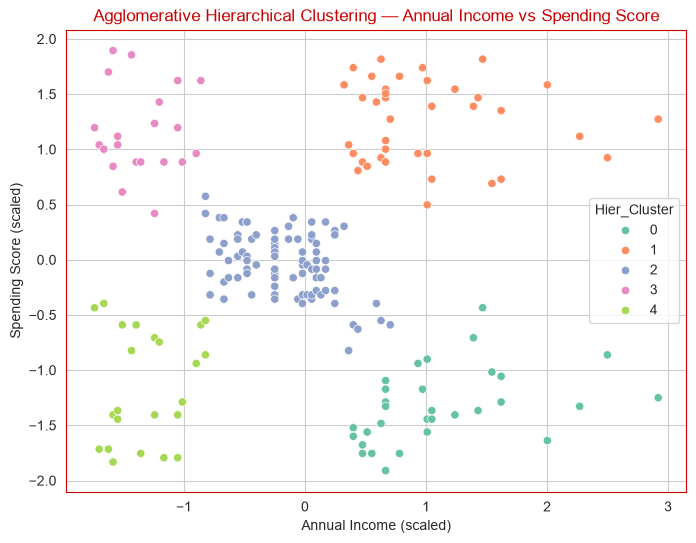

In [16]:
df['Hier_Cluster'] = AgglomerativeClustering(n_clusters=5, linkage='ward').fit_predict(df_2f)
plt.figure(figsize=(8,6))
sns.scatterplot(x=df_2f['Annual_Income'], y=df_2f['Spending_Score'], hue=df['Hier_Cluster'], palette='Set2')
plt.title('Agglomerative Hierarchical Clustering — Annual Income vs Spending Score')
plt.xlabel('Annual Income (scaled)'); plt.ylabel('Spending Score (scaled)'); plt.show()

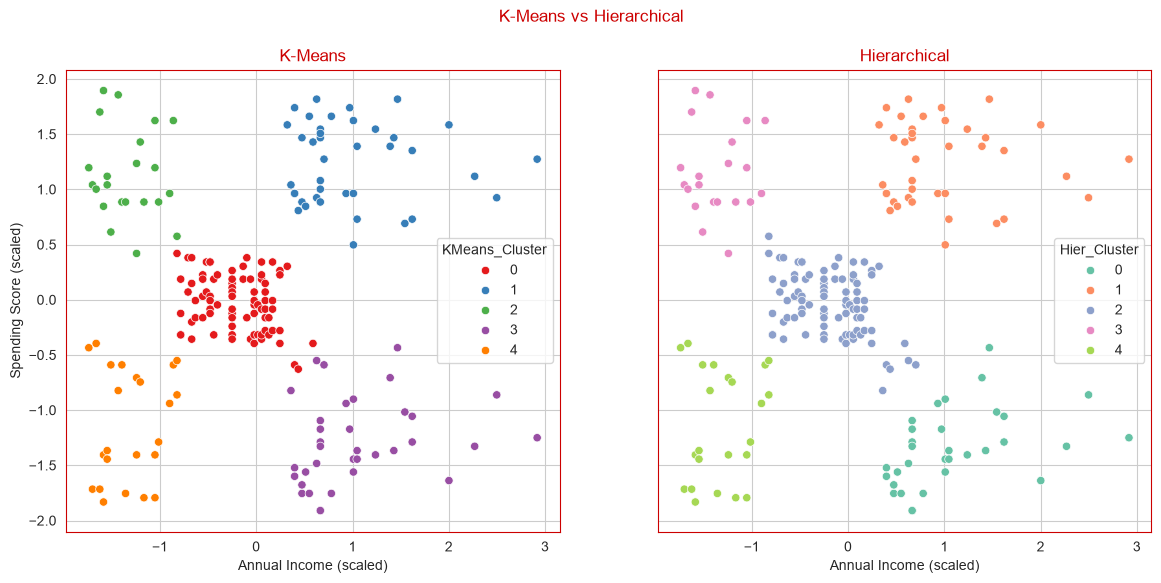

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14,6), sharey=True)
for a, col, pal, t in zip(ax, ['KMeans_Cluster','Hier_Cluster'], ['Set1','Set2'], ['K-Means','Hierarchical']):
    sns.scatterplot(x=df_2f['Annual_Income'], y=df_2f['Spending_Score'], hue=df[col], palette=pal, ax=a)
    a.set_title(t); a.set_xlabel('Annual Income (scaled)'); a.set_ylabel('Spending Score (scaled)')
plt.suptitle('K-Means vs Hierarchical', color='#CC0000'); plt.show()

The two methods mostly agree on the 5 core groups. Differences appear only for border-region customers between neighbouring groups. K-Means is centroid-based, so each point goes to the nearest centre. Hierarchical is connectivity-based, so points follow the merge history, which is built bottom-up from variance minimisation. That is why borderline points can land in different clusters.

In [19]:
df.groupby('Hier_Cluster')[['Age','Annual_Income','Spending_Score']].mean().style.background_gradient(cmap='Reds').format('{:.1f}')

,Age,Annual_Income,Spending_Score
Hier_Cluster,,,
0,41.0,89.4,15.6
1,32.7,86.5,82.1
2,42.5,55.8,49.1
3,25.3,25.1,80.0
4,45.2,26.3,20.9


Compare these means with the K-Means table. The five segment definitions should match, even though the cluster numbers may differ.

Task 5: DBSCAN

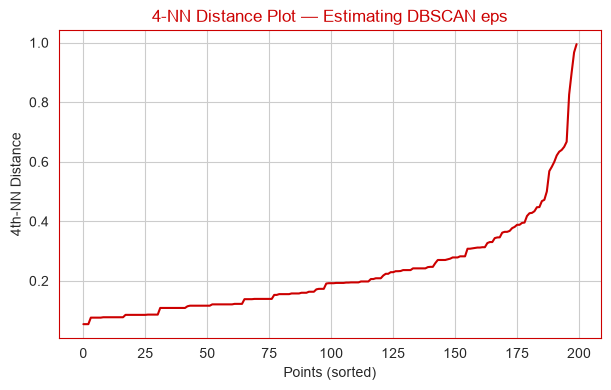

In [20]:
dist, _ = NearestNeighbors(n_neighbors=4).fit(df_2f).kneighbors(df_2f)
plt.figure(figsize=(7,4))
plt.plot(np.sort(dist[:,-1]), color='#CC0000')
plt.title('4-NN Distance Plot — Estimating DBSCAN eps')
plt.xlabel('Points (sorted)'); plt.ylabel('4th-NN Distance'); plt.show()

In [21]:
rows = []
for eps in [0.2,0.3,0.4,0.5,0.6]:
    for ms in [3,4,5,6]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(df_2f)
        m = lab != -1
        n_cl = len(set(lab[m]))
        s = silhouette_score(df_2f[m], lab[m]) if n_cl > 1 else np.nan
        rows.append([eps, ms, n_cl, (~m).sum(), s])
grid = pd.DataFrame(rows, columns=['eps','min_samples','n_clusters','n_noise','silhouette'])
grid

,eps,min_samples,n_clusters,n_noise,silhouette
0,0.2,3,13,44,0.469713
1,0.2,4,5,73,0.617282
2,0.2,5,7,77,0.585613
3,0.2,6,4,95,0.613836
4,0.3,3,9,14,0.472040
5,0.3,4,8,23,0.519746
6,0.3,5,7,35,0.524328
7,0.3,6,6,48,0.530244
8,0.4,3,4,10,0.395381
9,0.4,4,3,14,0.457570


In [22]:
eps, min_samples = 0.5, 5
db = DBSCAN(eps=eps, min_samples=min_samples).fit(df_2f)
df['DBSCAN_Cluster'] = db.labels_

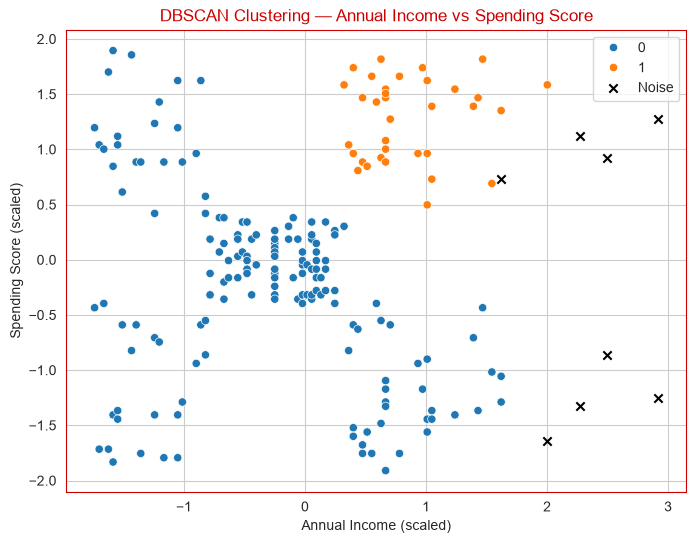

In [23]:
plt.figure(figsize=(8,6))
core = df['DBSCAN_Cluster'] != -1
sns.scatterplot(x=df_2f.loc[core,'Annual_Income'], y=df_2f.loc[core,'Spending_Score'], hue=df.loc[core,'DBSCAN_Cluster'], palette='tab10')
plt.scatter(df_2f.loc[~core,'Annual_Income'], df_2f.loc[~core,'Spending_Score'], c='black', marker='x', label='Noise')
plt.title('DBSCAN Clustering — Annual Income vs Spending Score')
plt.xlabel('Annual Income (scaled)'); plt.ylabel('Spending Score (scaled)'); plt.legend(); plt.show()

eps is the neighbourhood radius. min_samples is the number of points needed within that radius for a point to count as a core point. A larger eps or smaller min_samples gives fewer clusters and less noise. Noise points are those too far from any dense region to belong to a cluster.

Task 6: Algorithm Comparison & Business Insights

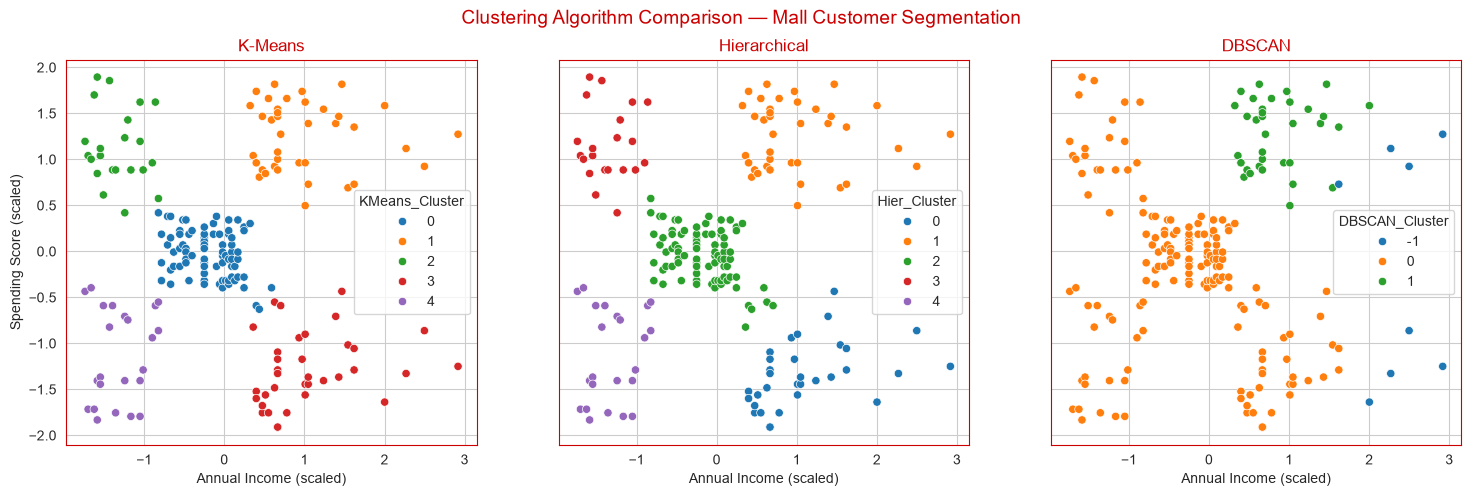

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(18,5), sharey=True)
for a, col, t in zip(ax, ['KMeans_Cluster','Hier_Cluster','DBSCAN_Cluster'], ['K-Means','Hierarchical','DBSCAN']):
    sns.scatterplot(x=df_2f['Annual_Income'], y=df_2f['Spending_Score'], hue=df[col], palette='tab10', ax=a)
    a.set_title(t); a.set_xlabel('Annual Income (scaled)'); a.set_ylabel('Spending Score (scaled)')
plt.suptitle('Clustering Algorithm Comparison — Mall Customer Segmentation', color='#CC0000', fontsize=14)
plt.show()

In [25]:
res = []
for name, col in [('K-Means','KMeans_Cluster'),('Hierarchical','Hier_Cluster'),('DBSCAN','DBSCAN_Cluster')]:
    m = df[col] != -1
    X, y = df_2f[m], df.loc[m, col]
    res.append([name, y.nunique(), silhouette_score(X,y), davies_bouldin_score(X,y), calinski_harabasz_score(X,y)])
pd.DataFrame(res, columns=['Algorithm','n_clusters','Silhouette','Davies-Bouldin','Calinski-Harabasz']).round(3)

,Algorithm,n_clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-Means,5,0.555,0.572,248.649
1,Hierarchical,5,0.554,0.578,244.410
2,DBSCAN,2,0.388,0.789,85.390


Higher silhouette and Calinski-Harabasz are better, and lower Davies-Bouldin is better. Write which algorithm wins after you see your numbers. K-Means and Hierarchical will likely be very close. DBSCAN can score well on silhouette only because its noise points are excluded, so say that in your explanation.

Business Insights for Mall Management
(a) Segments (K-Means): High Income/High Spend, High Income/Low Spend, Mid/Mid, Low Income/High Spend, Low Income/Low Spend.
(b) Actions:

High Income/High Spend: loyalty rewards and VIP events.
High Income/Low Spend: personalised premium offers to raise engagement.
Mid/Mid: seasonal promotions and bundles.
Low Income/High Spend: budget deals and installment offers.
Low Income/Low Spend: low-cost discount coupons.

(c) Recommendation: K-Means for deployment, because it is the most interpretable and easy to explain to marketing teams. DBSCAN is better when cluster shapes are unknown, and Hierarchical is better when a dendrogram is needed for a management presentation.